In [3]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
import math

# **1. Подберите параметры алгоритма разрастания регионов так, чтобы был выделен весь участок газона.**

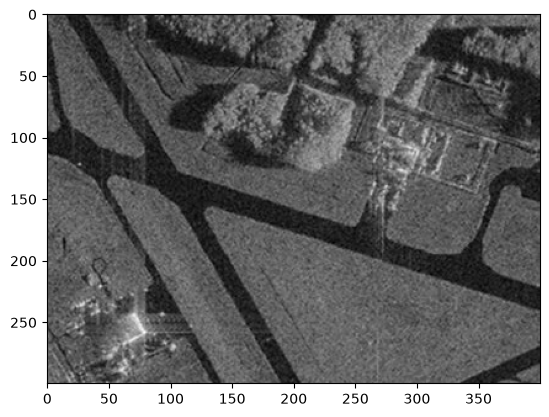

In [2]:
image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap="gray")
plt.show()

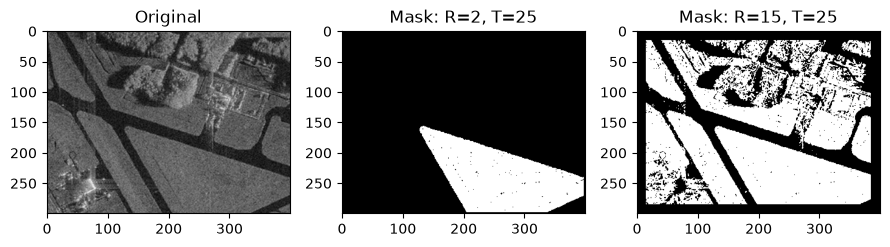

In [12]:
def homo_average(img, mask, point, T):
    av_val = img[mask > 0].sum() / np.count_nonzero(img[mask > 0])
                                                            
    if abs(av_val - img[point]) <= T:
        return True
    
    return False

def region_growing(image, seed_point,homo_fun,r, T):
    mask = np.zeros(image_gray.shape, np.uint8)
    mask[seed_point] = 1
    count = 1
    while count > 0:
        count = 0
        local_mask = np.zeros(image_gray.shape, np.uint8)
        for i in range(r,image.shape[0] - r):
            for j in range(r,image.shape[1] - r):
                if mask[i,j]==0 and mask[i - r:i + r, j-r: j+r].sum() > 0:
                    if homo_fun(image, mask, (i,j), T):
                        local_mask[i,j] = 1
        count = np.count_nonzero(local_mask)
        mask += local_mask
        
    return mask*255

images = {"Original": image_gray}

seed_point = (250,250)
r = 2
t = 25

mask1 = region_growing(image_gray, seed_point, homo_average, r, t)
images[f"Mask: R={r}, T={t}"] = mask1

r = 15
t = 25
mask2 = region_growing(image_gray, seed_point, homo_average, r, t)
images[f"Mask: R={r}, T={t}"] = mask2

fig, axs = plt.subplots(1, 3, figsize=(9, 5))

col = 0
for col, (key, img) in enumerate(images.items()):
    axs[col].imshow(img, cmap='gray')
    axs[col].set_title(key)

plt.tight_layout()
plt.show()

# **2. Реализуйте вычисление критерия однородности, отличного от представленного. Сравните результаты.**

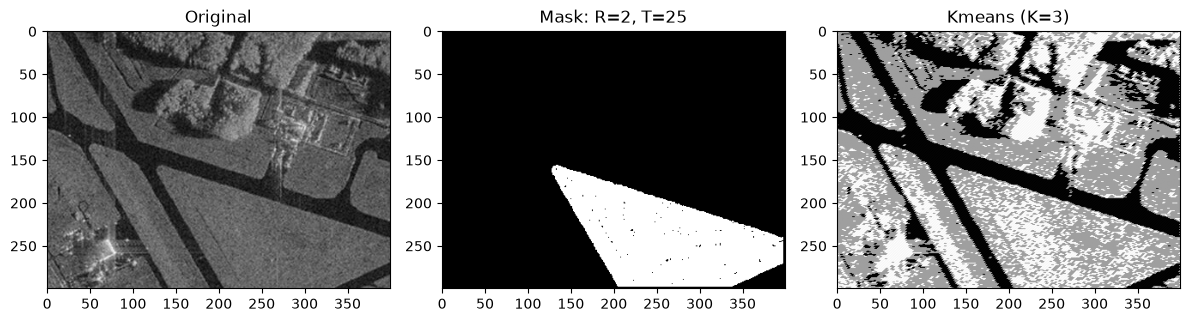

In [11]:
z = np.float32(image_gray.reshape((-1,3)))

K = 3
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0) 

ret, label, center = cv2.kmeans(z, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Restore image
center = np.uint8(center)
res = center[label.flatten()]
res = res.reshape((image_gray.shape))
images[f"Kmeans (K={K})"] = res
# Show images
fig, axs = plt.subplots(1, 3, figsize=(12, 5))

col = 0
for col, (key, img) in enumerate(images.items()):
    axs[col].imshow(img, cmap='gray')
    axs[col].set_title(key)

plt.tight_layout()
plt.show()

**Вывод:** Если нужно выделить один конкретный объект (как наш участок газона) — Region Growing лучше. Он дает чистую и ровную маску.
K-means — это инструмент для общей разбивки картинки на цвета. Он не знает, где объект, и путается в текстурах, поэтому для такой задачи он подходит хуже.

# **3. Применить алгоритм сегментации watershed+distance transform для задачи подсчета пальмовых деревьев.**

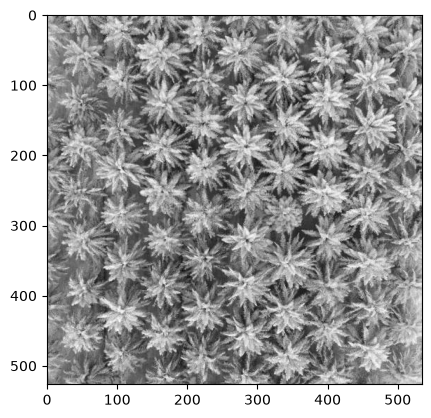

In [5]:
palm = cv2.imread("palm_1.JPG")
palm_gray = cv2.cvtColor(palm, cv2.COLOR_BGR2GRAY)
plt.imshow(palm_gray, cmap="gray")
plt.show()

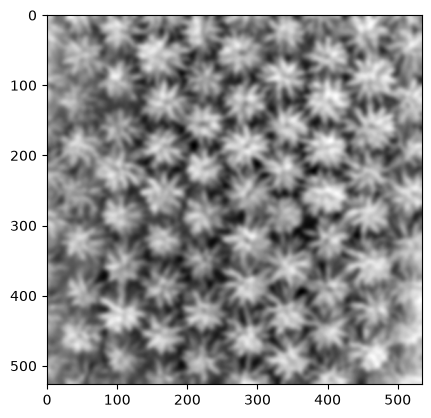

In [6]:
palm_gb = cv2.GaussianBlur(palm_gray, (19, 19), 0)
plt.imshow(palm_gb, cmap="gray")


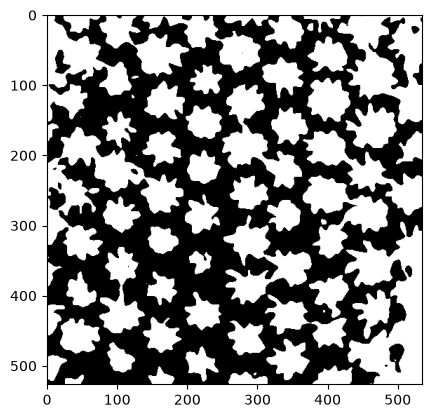

In [9]:
ret, thresh = cv2.threshold(palm_gb,0,255, cv2.THRESH_BINARY+cv2.THRESH_OTSU)
plt.imshow(thresh, cmap="gray")





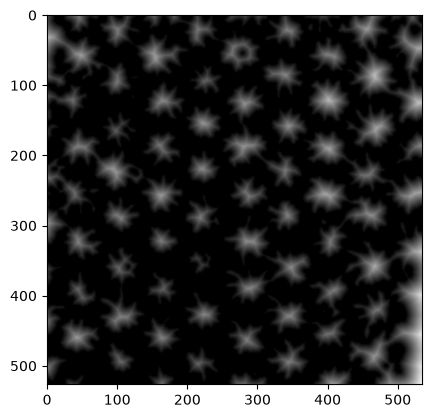

In [10]:
dist = cv2.distanceTransform(thresh, cv2.DIST_L2, 5) 
plt.imshow(dist, cmap="gray")




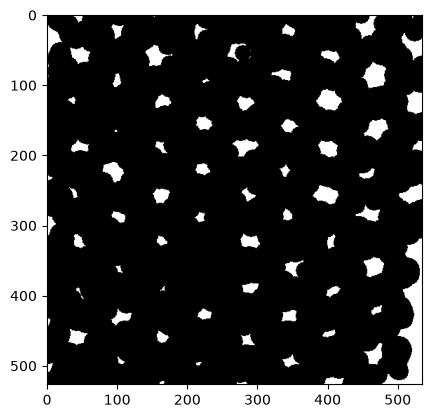

In [21]:
ret, sure_fg = cv2.threshold(dist, 0.33 * dist.max(), 255, cv2.THRESH_BINARY) 
sure_fg = sure_fg.astype(np.uint8)
plt.imshow(sure_fg, cmap='gray')


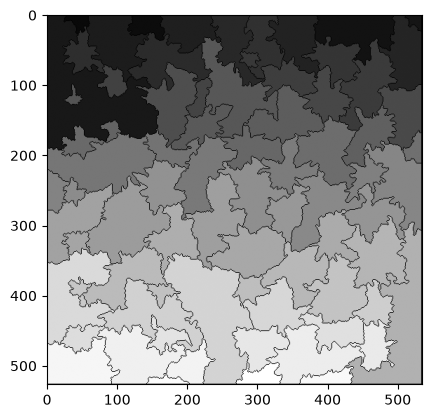

In [25]:
ret, markers = cv2.connectedComponents(sure_fg)
markers = cv2.watershed(palm, markers)

label = np.unique(markers)
count = np.count_nonzero(label > 1)

palm[markers == -1] = [0, 0, 255]
plt.imshow(markers, cmap='gray')

In [26]:
print(f'{count} palms on the picture')

78 palms on the picture


Количество выделенных пальм: 78


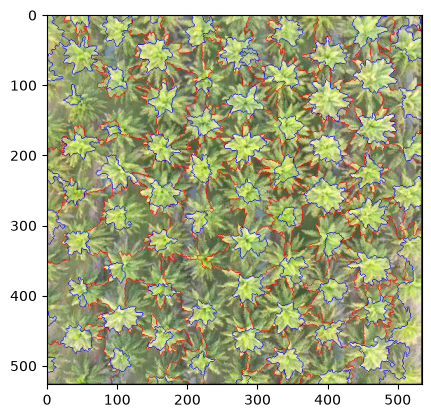

In [28]:
ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[(thresh > 0) & (sure_fg == 0)] = 0
markers = cv2.watershed(palm, markers)

label = np.unique(markers)
count = np.count_nonzero(label > 1)
print('Количество выделенных пальм:', count)

palm[markers == -1] = [255, 0, 0]
plt.imshow(cv2.cvtColor(palm, cv2.COLOR_BGR2RGB))